In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(101)
n = 1200

departments = np.random.choice(
    ['Engineering', 'Marketing', 'Sales', 'Operations', 'Customer Support'],
    size=n,
    p=[0.30, 0.22, 0.25, 0.13, 0.10]
)

expense_type = np.random.choice(
    ['Cloud & Software', 'Payroll & Contractors', 'Ad Spend', 'Logistics & Ops', 'Travel & Events'],
    size=n,
    p=[0.32, 0.28, 0.20, 0.12, 0.08]
)

base_amounts = {
    'Engineering': np.random.gamma(shape=3.0, scale=45000, size=n),
    'Marketing': np.random.gamma(shape=2.5, scale=55000, size=n),
    'Sales': np.random.gamma(shape=2.8, scale=40000, size=n),
    'Operations': np.random.gamma(shape=2.2, scale=35000, size=n),
    'Customer Support': np.random.gamma(shape=2.0, scale=22000, size=n)
}

amount = np.zeros(n)
for dept, vals in base_amounts.items():
    mask = (departments == dept)
    amount[mask] = vals[mask]

outlier_idx = np.random.choice(n, size=12, replace=False)
amount[outlier_idx] = np.random.uniform(420000, 680000, size=12)

df_fin = pd.DataFrame({
    'tx_id': [f"TX-{5000 + i}" for i in range(n)],
    'tx_date': pd.to_datetime(pd.date_range('2026-01-01', '2026-09-30', periods=n).strftime('%Y-%m-%d')),
    'department': departments,
    'expense_type': expense_type,
    'amount': np.round(amount, 2)
})

df_fin.head()



,tx_id,tx_date,department,expense_type,amount
0,TX-5000,2026-01-01,Marketing,Cloud & Software,258929.53
1,TX-5001,2026-01-01,Sales,Travel & Events,31611.15
2,TX-5002,2026-01-01,Engineering,Payroll & Contractors,125094.78
3,TX-5003,2026-01-01,Engineering,Ad Spend,193658.11
4,TX-5004,2026-01-01,Sales,Payroll & Contractors,57569.42


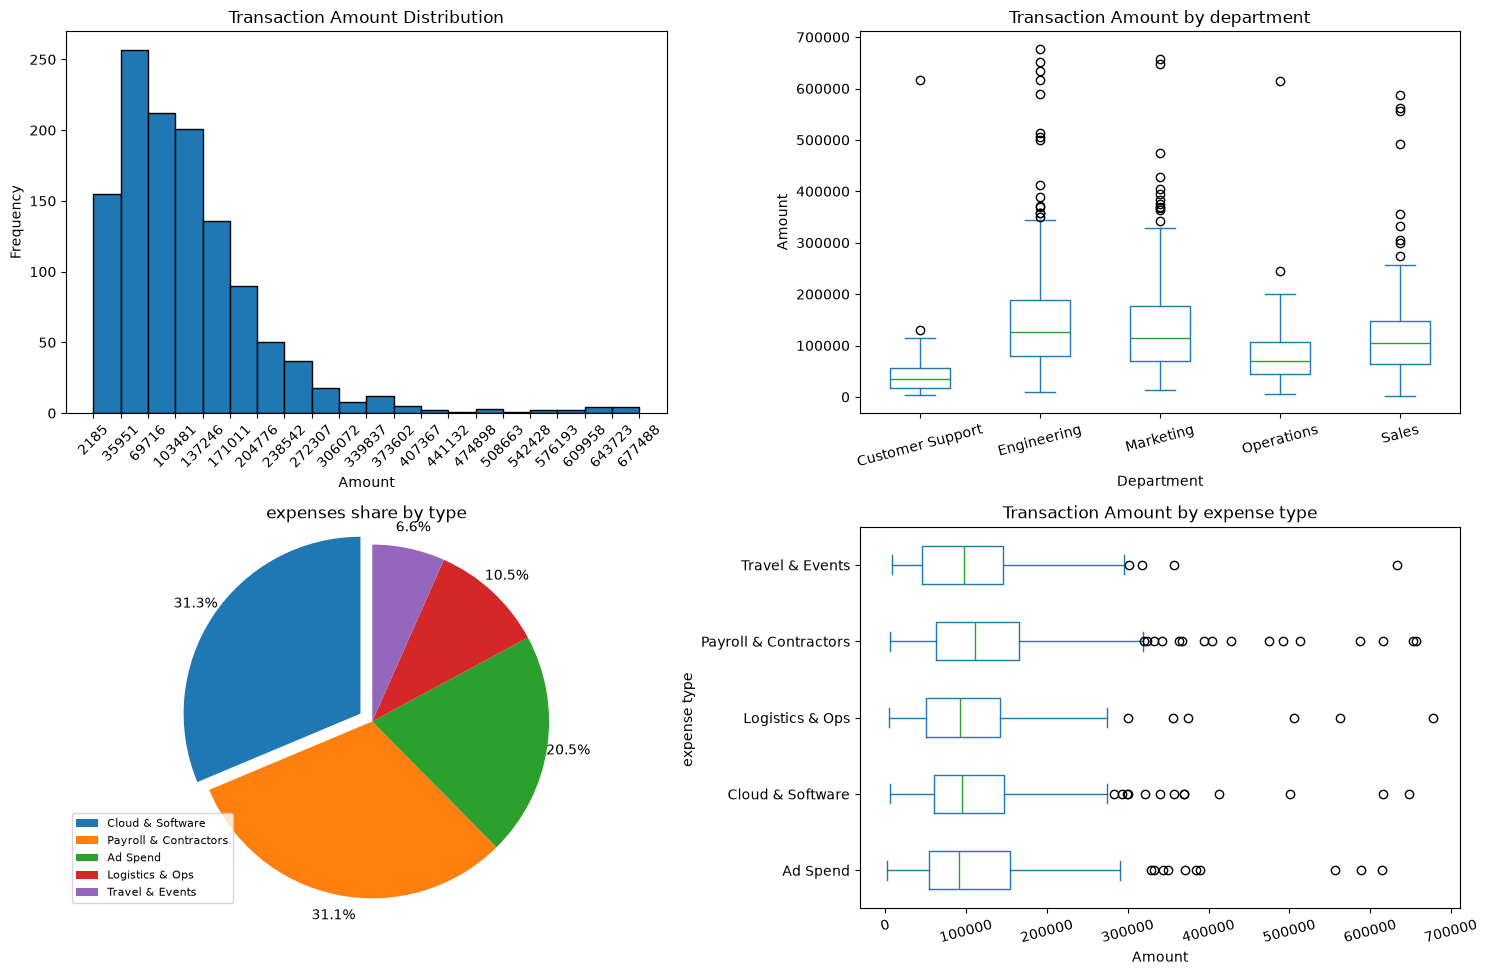

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
#histogram
count,bin_edges = np.histogram(df_fin['amount'],bins = 20)
df_fin['amount'].plot(kind = 'hist',
            bins = 20,
            xticks = bin_edges,
            edgecolor = 'black',
            ax=axes[0, 0]
            )
axes[0, 0].set_title('Transaction Amount Distribution')
axes[0, 0].set_xlabel('Amount')
axes[0, 0].tick_params(axis='x', rotation=45)

#boxplot
boxplotData = df_fin[['amount','department']]
boxplotData.plot(kind='box',
                 column = 'amount', by='department',
                 ax=axes[0,1])
axes[0, 1].set_title('Transaction Amount by department')
axes[0, 1].set_xlabel('Department')
axes[0, 1].set_ylabel('Amount')
axes[0, 1].tick_params(axis='x', rotation=15)  # Keeps 'Customer Support' and 'Engineering' from touching
fig.suptitle('')

#piechart
expense_totals = df_fin.groupby('expense_type')['amount'].sum().sort_values(ascending=False)

# Largest item is guaranteed to be first
explode_list = [0.08] + [0] * (len(expense_totals) - 1)
expense_totals.plot(kind='pie',
                    explode = explode_list,
                    ax=axes[1,0],
                    autopct='%1.1f%%',
                    startangle = 90,
                    labels = None,
                    pctdistance = 1.12
                    )
axes[1,0].set_title('expenses share by type')
axes[1, 0].set_ylabel('')
axes[1, 0].axis('equal')
axes[1, 0].legend(labels=expense_totals.index, loc='lower left', fontsize=8)

#box plot
#boxplot
boxplotData = df_fin[['amount','expense_type']]
boxplotData.plot(kind='box',
                 column = 'amount', by='expense_type',
                 ax=axes[1,1],vert=False)
axes[1, 1].set_title('Transaction Amount by expense type')
axes[1, 1].set_xlabel('Amount')
axes[1, 1].set_ylabel('expense type ')
axes[1, 1].tick_params(axis='x', rotation=15)  # Keeps 'Customer Support' and 'Engineering' from touching
fig.suptitle('')

plt.tight_layout()
plt.show()


In [8]:
#histogram
count,bin_edges = np.histogram(df_fin['amount'],bins = 20)
df_fin['amount'].plot(kind = 'hist',
            bins = 20,
            xticks = bin_edges,
            edgecolor = 'black',
            ax=axes[0, 0]
            )
axes[0, 0].set_title('Transaction Amount Distribution')
axes[0, 0].set_xlabel('Amount')
axes[0, 0].tick_params(axis='x', rotation=45)


In [9]:
#boxplot
boxplotData = df_fin[['amount','department']]
boxplotData.plot(kind='box',
                 column = 'amount', by='department',
                 ax=axes[0,1])
axes[0, 1].set_title('Transaction Amount by department')
axes[0, 1].set_xlabel('Department')
axes[0, 1].set_ylabel('Amount')
axes[0, 1].tick_params(axis='x', rotation=15)  # Keeps 'Customer Support' and 'Engineering' from touching
fig.suptitle('')

Text(0.5, 0.98, '')

In [10]:
#piechart
expense_totals = df_fin.groupby('expense_type')['amount'].sum().sort_values(ascending=False)

# Largest item is guaranteed to be first
explode_list = [0.08] + [0] * (len(expense_totals) - 1)
expense_totals.plot(kind='pie',
                    explode = explode_list,
                    ax=axes[1,0],
                    autopct='%1.1f%%',
                    startangle = 90,
                    labels = None,
                    pctdistance = 1.12
                    )
axes[1,0].set_title('expenses share by type')
axes[1, 0].set_ylabel('')
axes[1, 0].axis('equal')
axes[1, 0].legend(labels=expense_totals.index, loc='upper left', fontsize=8)

In [13]:
#box plot
#boxplot
boxplotData = df_fin[['amount','expense_type']]
boxplotData.plot(kind='box',
                 column = 'amount', by='expense_type',
                 ax=axes[1,1])
axes[1, 1].set_title('Transaction Amount by expense type')
axes[1, 1].set_xlabel('expense type')
axes[1, 1].set_ylabel('Amount')
axes[1, 1].tick_params(axis='x', rotation=15)  # Keeps 'Customer Support' and 'Engineering' from touching
fig.suptitle('')

Text(0.5, 0.98, '')

In [15]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>